# Recognising Letters, Digits and Symbols with Keras: an OCR Project

## Abstract

In [1]:
# The abstract quotes numbers from the saved experiment results instead of typing them in,
# so it cannot drift away from what the notebook actually measured.
import json
from pathlib import Path
from IPython.display import Markdown, display

_root = Path.cwd()
while not (_root / "pyproject.toml").exists():
    _root = _root.parent
_read = lambda d: [json.loads(p.read_text()) for p in sorted((_root / "experiments/results" / d).glob("*.json"))]
try:
    _final, _cmp = _read("final")[0], _read("comparison")
    _by = {}
    for _r in _cmp:
        _by.setdefault(_r["cfg"]["family"], []).append(_r["val_acc"])
    _mean = {f: sum(v) / len(v) for f, v in _by.items()}
    _rank = sorted(_mean, key=_mean.get, reverse=True)
    _names = {"mlp": "MLP", "cnn": "plain CNN", "resnet": "ResNet-style CNN", "cnn_bilstm": "CNN + BiLSTM"}
    display(Markdown(
        "In this project we train neural networks to recognise a single character from a 28x28 image. "
        "The classes are the 94 printable keyboard characters: capital letters, small letters, digits and "
        "32 common symbols. Because no single dataset covers all of them, we combined EMNIST (handwritten "
        "letters and digits), HASYv2 (handwritten symbols) and rendered system fonts (printed symbols), "
        "using separate fonts and separate HASYv2 writers for testing. We compared four Keras models "
        "(" + ", ".join(_names[f] for f in _names) + "), changed the number of training epochs and of "
        "hidden layers, repeated the best version of each model with three random seeds, and trained the "
        f"winner, the **{_names[_final['cfg']['family']]}**"
        + (f" (a close call with the {_names[_rank[1]]})" if (_mean[_rank[0]] - _mean[_rank[1]]) < 0.01 else "")
        + ", on the full training set. "
        f"It reaches **{_final['test_acc']:.1%}** accuracy on the held-out test set. "
        "Most of the remaining errors are between characters that look the same in isolation "
        "(for example `c`/`C`, `o`/`O`/`0` and `l`/`I`/`1`)."))
except (FileNotFoundError, IndexError, KeyError):
    display(Markdown("*Run the experiments (`python scripts/run_experiments.py`) first, then re-run this cell.*"))

In this project we train neural networks to recognise a single character from a 28x28 image. The classes are the 94 printable keyboard characters: capital letters, small letters, digits and 32 common symbols. Because no single dataset covers all of them, we combined EMNIST (handwritten letters and digits), HASYv2 (handwritten symbols) and rendered system fonts (printed symbols), using separate fonts and separate HASYv2 writers for testing. We compared four Keras models (MLP, plain CNN, ResNet-style CNN, CNN + BiLSTM), changed the number of training epochs and of hidden layers, repeated the best version of each model with three random seeds, and trained the winner, the **ResNet-style CNN** (a close call with the plain CNN), on the full training set. It reaches **84.7%** accuracy on the held-out test set. Most of the remaining errors are between characters that look the same in isolation (for example `c`/`C`, `o`/`O`/`0` and `l`/`I`/`1`).

**Contents:** 1 Introduction - 2 Related work - 3 Setting up - 4 Dataset - 5 Preprocessing -
6 Models - 7 Experiment 1: epochs - 8 Experiment 2: hidden layers - 9 Experiment 3: comparing models -
10 Final model - 11 Evaluation - 12 Live demo - 13 Limitations - 14 Conclusion - References

## 1. Introduction

OCR (optical character recognition) means turning a picture of text into actual text. Phone scanners, number-plate readers and cheque or form processing all use it. In this project we do the smallest version of the problem: look at **one character** and say which one it is. The catch is that we want the whole keyboard, so capital letters, small letters, the digits 0-9 and the usual symbols like `! @ # $ % & * ( )`. That makes 94 classes.

What we set out to do:
1. build a classifier for all 94 characters with Keras and TensorFlow
2. see what changing the number of training epochs does to the accuracy
3. see what changing the number of hidden layers does
4. compare at least three different deep learning models (we ended up with four) and pick the best one

Some characters can't be told apart even by a person when they are shown alone, for example `o`, `O` and `0`. So part of the work was deciding how to measure success fairly (Section 11).

## 2. Related work

Recognising handwritten digits is a classic problem. The MNIST dataset (LeCun et al., 1998) is the usual starting point, EMNIST (Cohen et al., 2017) adds letters in the same 28x28 format, and HASYv2 (Thoma, 2017) has handwritten maths and keyboard symbols. Convolutional networks work best on these datasets because strokes are local patterns that look the same wherever they appear in the image.

What makes our task harder than MNIST is that many of the 94 classes look identical once the image is cropped to the ink and scaled: `c/C`, `k/K`, `m/M`, `o/O/0`, `p/P`, `s/S`, `u/U`, `v/V`, `w/W`, `x/X`, `y/Y`, `z/Z` and `l/I/1/|` (`. , '` are also easy to mix up, but we did not merge those in the second accuracy). A classifier that only sees one glyph can't separate these. So we report two accuracies, a strict one (the exact character) and one where these look-alike groups count as the same, and we look at the errors instead of hiding them.

The four models we compare:
1. **MLP**: a plain fully connected network. It is our baseline and ignores the 2-D structure of the image.
2. **Plain CNN**: stacked 3x3 convolutions with batch normalisation, max-pooling and dropout (Ioffe & Szegedy, 2015; Srivastava et al., 2014).
3. **ResNet-style CNN**: convolution blocks with shortcut connections, which make deeper networks easier to train (He et al., 2016).
4. **CNN + BiLSTM**: a CNN whose output columns are read from left to right by a bidirectional LSTM (Hochreiter & Schmidhuber, 1997; Schuster & Paliwal, 1997). This is the idea behind CRNN text recognisers (Shi et al., 2017).

All of them are trained with the Adam optimiser (Kingma & Ba, 2015) and cross-entropy loss.

## 3. Setting up: libraries and hardware

In [2]:
# --- Imports and project root ---------------------------------------------------------
import os, sys, time, platform, warnings
from pathlib import Path

# The notebook may be started from notebooks/ or the repo root: walk up to pyproject.toml.
ROOT = Path.cwd()
while not (ROOT / "pyproject.toml").exists():
    ROOT = ROOT.parent
os.chdir(ROOT)                                     # all relative paths (data/, models/...) resolve here
sys.path[:0] = [str(ROOT), str(ROOT / "scripts")]  # import `hcr` and the experiment driver
os.environ.setdefault("TF_CPP_MIN_LOG_LEVEL", "2")  # keep TensorFlow's C++ logging quiet
warnings.filterwarnings("ignore")

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import tensorflow as tf
import keras
from IPython.display import display, Markdown

# --- Plot style: one consistent, colour-blind-safe palette (Okabe-Ito) -----------------
PALETTE = {"mlp": "#E69F00", "cnn": "#0072B2", "resnet": "#009E73", "cnn_bilstm": "#CC79A7"}
LABELS = {"mlp": "MLP", "cnn": "Plain CNN", "resnet": "ResNet-style CNN", "cnn_bilstm": "CNN + BiLSTM"}
plt.rcParams.update({
    "figure.dpi": 110, "axes.spines.top": False, "axes.spines.right": False,
    "axes.grid": True, "grid.alpha": 0.25, "axes.titleweight": "bold", "font.size": 10,
})
Path("reports/figures").mkdir(parents=True, exist_ok=True)

print("Python      :", platform.python_version())
print("TensorFlow  :", tf.__version__)
print("Keras       :", keras.__version__, "(backend:", keras.backend.backend() + ")")
print("CPU threads :", os.cpu_count())
gpus = tf.config.list_physical_devices("GPU")
print("GPUs visible:", gpus if gpus else "none")

Python      : 3.13.14
TensorFlow  : 2.20.0
Keras       : 3.15.1 (backend: tensorflow)
CPU threads : 32
GPUs visible: none


In [3]:
# --- Be explicit about the compute device actually used ---------------------------------
if gpus:
    display(Markdown(f"**Training device: GPU** ({gpus[0].name})."))
else:
    display(Markdown(
        "**Training device: CPU only.** The laptop has an NVIDIA RTX 4060, but TensorFlow >= 2.11 "
        "has no native-Windows GPU build, and WSL2/Docker (the usual workaround) is unavailable "
        "because hardware virtualisation is disabled in firmware. All experiments therefore ran on "
        "the CPU (32 threads); to keep this tractable the sweeps use training subsets (stated in "
        "each section) and only the final model sees the full training set. The code is "
        "device-agnostic: on a machine where TensorFlow sees a GPU it will use it unchanged."
    ))

**Training device: CPU only.** The laptop has an NVIDIA RTX 4060, but TensorFlow >= 2.11 has no native-Windows GPU build, and WSL2/Docker (the usual workaround) is unavailable because hardware virtualisation is disabled in firmware. All experiments therefore ran on the CPU (32 threads); to keep this tractable the sweeps use training subsets (stated in each section) and only the final model sees the full training set. The code is device-agnostic: on a machine where TensorFlow sees a GPU it will use it unchanged.

## 4. Dataset

### 4.1 Sources and why we combine them

| Source | Content | Role |
|---|---|---|
| **EMNIST ByClass** | ~800k real handwritten digits, capitals and small letters (62 classes) | main handwritten data; keeps capital/small letters distinct |
| **HASYv2** | real handwritten symbols from many writers | handwritten keyboard symbols (only some of the 32 exist in HASYv2) |
| **System fonts** (Pillow) | printed glyphs, augmented (rotation, shear, stroke, blur, noise) | covers the symbols HASYv2 lacks; **printed, not handwritten** |

We did not use EMNIST *Balanced*, which an earlier version of this project used. It merges the capital and small versions of 15 letters into one class, so it can never learn the difference between `c` and `C`. The old "keyboard symbols" benchmark (100% accuracy) also meant nothing, because every symbol was drawn in one font and the train and test images were identical. The font split below replaces it.

### 4.2 Keeping the test data separate
* Fonts are split by font file: a file used for testing never appears in training. This is weaker than it sounds, because bold and italic styles of one family can end up on different sides (`arial.ttf` and `arialbi.ttf` are training fonts, but `arialbd.ttf` and `ariali.ttf` are test fonts), so the printed-font test accuracy is a little optimistic.
* HASYv2 is split by writer id, so no writer id is in both train and test. EMNIST comes without writer information, so its validation split can share writers with its training split.
* Exact duplicate images between train and validation/test were removed (checked again below).
* Every choice (which model, how many layers) is made on the validation set. The test set is only used to report numbers.

In [4]:
# --- Load (or build and cache) the unified 94-class dataset ----------------------------
from hcr.unified import load_unified, class_groups, AMBIGUOUS_GROUPS, pixel_hashes

t0 = time.time()
data = load_unified()          # float32 images (N, 28, 28, 1) in [0, 1]; int labels 0..93
print(f"loaded in {time.time() - t0:.1f}s | classes: {len(data.classes)}")
print("train", data.x_train.shape, "| val", data.x_val.shape, "| test", data.x_test.shape)

SOURCE = {0: "EMNIST (handwritten)", 1: "HASYv2 (handwritten)", 2: "Fonts (printed)"}
summary = pd.DataFrame({
    split: {SOURCE[s]: int((getattr(data, f"source_{split}") == s).sum()) for s in SOURCE}
    for split in ("train", "val", "test")
})
summary.loc["Total"] = summary.sum()
display(summary)

loaded in 5.4s | classes: 94
train (742742, 28, 28, 1) | val (80252, 28, 28, 1) | test (123533, 28, 28, 1)


,train,val,test
EMNIST (handwritten),628142,69788,116318
HASYv2 (handwritten),10334,45,165
Fonts (printed),104266,10419,7050
Total,742742,80252,123533


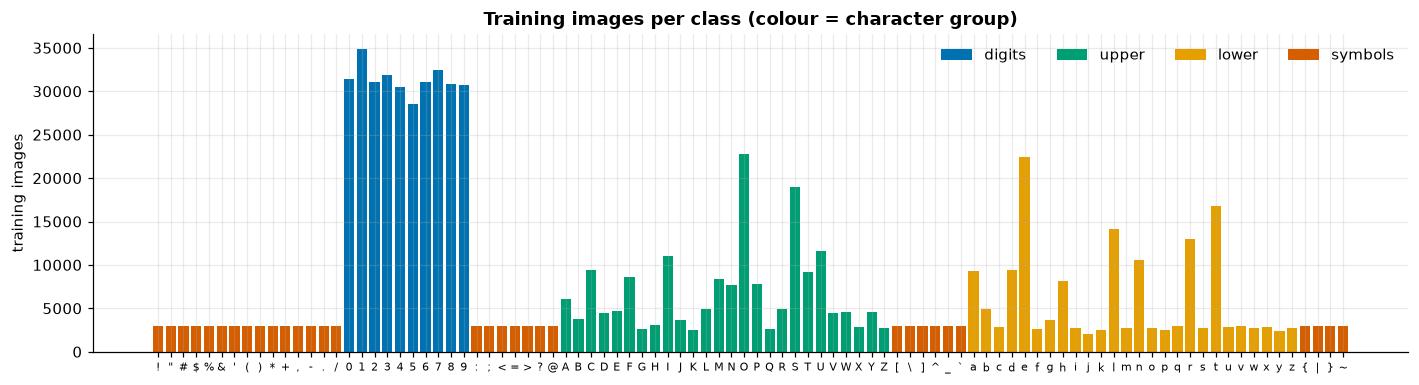

,train images
digits,313532
upper,177863
lower,155347
symbols,96000


In [5]:
# --- Class balance per group ------------------------------------------------------------
groups = class_groups(data.classes)          # {'digits': [...], 'upper': [...], ...} of label indices
counts = np.bincount(data.y_train, minlength=len(data.classes))
group_of = {i: g for g, idx in groups.items() for i in idx}
group_colour = {"digits": "#0072B2", "upper": "#009E73", "lower": "#E69F00", "symbols": "#D55E00"}

fig, ax = plt.subplots(figsize=(13, 3.6))
ax.bar(range(len(counts)), counts, color=[group_colour[group_of[i]] for i in range(len(counts))])
ax.set_xticks(range(len(counts)))
ax.set_xticklabels(data.classes, fontsize=7)
ax.set_ylabel("training images")
ax.set_title("Training images per class (colour = character group)")
for g, c in group_colour.items():
    ax.bar(0, 0, color=c, label=g)
ax.legend(ncol=4, frameon=False)
plt.tight_layout(); plt.savefig("reports/figures/class_balance.png"); plt.show()

display(pd.Series({g: int(counts[idx].sum()) for g, idx in groups.items()},
                  name="train images").to_frame())

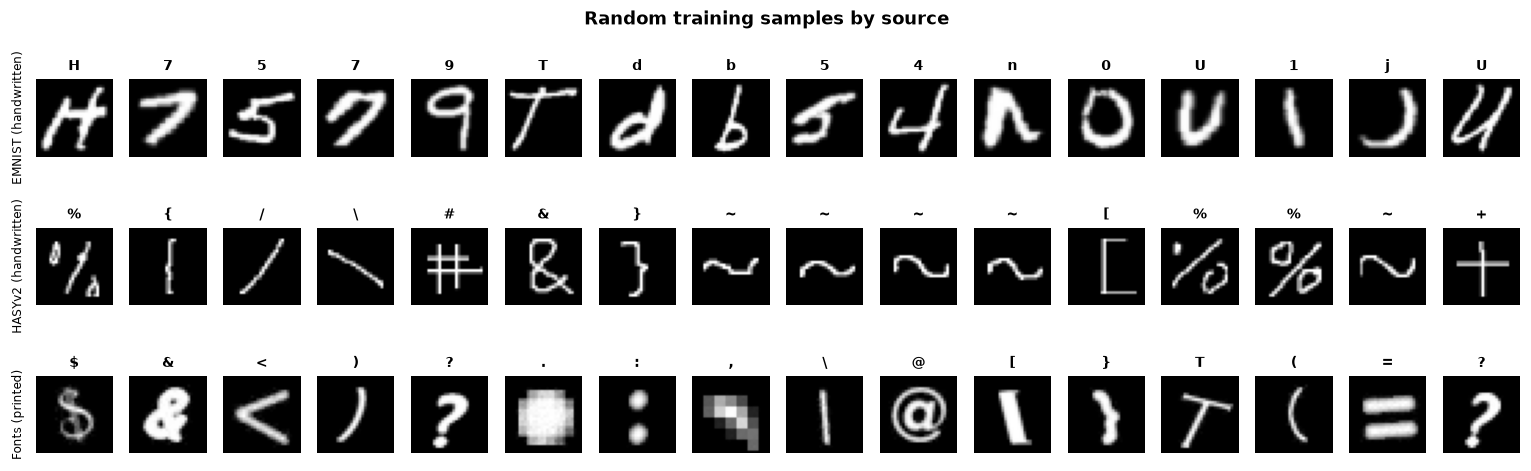

In [6]:
# --- What the data looks like: one row per source ---------------------------------------
rng = np.random.default_rng(0)
fig, axes = plt.subplots(3, 16, figsize=(14, 4.4))
for row, s in enumerate(SOURCE):
    idx = np.flatnonzero(data.source_train == s)
    pick = rng.choice(idx, 16, replace=False)
    for col, i in enumerate(pick):
        axes[row, col].imshow(data.x_train[i, ..., 0], cmap="gray")
        axes[row, col].set_title(data.classes[data.y_train[i]], fontsize=9)
        axes[row, col].axis("off")
    axes[row, 0].text(-0.15, 0.5, SOURCE[s], transform=axes[row, 0].transAxes, rotation=90,
                      va="center", ha="right", fontsize=8)
plt.suptitle("Random training samples by source", fontweight="bold")
plt.tight_layout(); plt.savefig("reports/figures/samples_by_source.png"); plt.show()

In [7]:
# --- Verify the leakage controls instead of just asserting them -------------------------
rows = []
for s in SOURCE:
    train_hashes = set(pixel_hashes(data.x_train[data.source_train == s]))
    for split in ("val", "test"):
        x = getattr(data, f"x_{split}")[getattr(data, f"source_{split}") == s]
        dup = sum(h in train_hashes for h in pixel_hashes(x))
        rows.append({"source": SOURCE[s], "split": split, "images": len(x), "exact duplicates of train": dup})
display(pd.DataFrame(rows))

from hcr.hasy import COVERAGE
print("HASYv2 (handwritten) covers", len(COVERAGE["covered"]), "of 32 symbols:", "".join(COVERAGE["covered"]))
print("Printed-font only          :", "".join(COVERAGE["missing"]))

,source,split,images,exact duplicates of train
0,EMNIST (handwritten),val,69788,0
1,EMNIST (handwritten),test,116318,0
2,HASYv2 (handwritten),val,45,0
3,HASYv2 (handwritten),test,165,0
4,Fonts (printed),val,10419,0
5,Fonts (printed),test,7050,0


HASYv2 (handwritten) covers 17 of 32 symbols: #$%&*-+[]{}\|<>/~
Printed-font only          : !@()_=;:'",.?^`


In [8]:
# Even the 17 symbols that HASYv2 covers are not purely handwritten in our training set:
# the font renders are added on top, so what fraction of each symbol's training images is handwritten?
rows = []
for c in COVERAGE["covered"]:
    tr = data.y_train == data.classes.index(c)
    rows.append({"symbol": c, "handwritten (HASYv2)": int((tr & (data.source_train == 1)).sum()),
                 "printed (fonts)": int((tr & (data.source_train == 2)).sum())})
share = pd.DataFrame(rows).set_index("symbol")
share["handwritten share"] = share["handwritten (HASYv2)"] / share.sum(axis=1)
display(share.T.style.format("{:.0f}", subset=pd.IndexSlice[share.columns[:2], :])
        .format("{:.0%}", subset=pd.IndexSlice[["handwritten share"], :]))
mostly_printed = list(share.index[share["handwritten share"] < 0.5])
display(Markdown(f"For {len(mostly_printed)} of these 17 symbols (" + " ".join(f"`{c}`" for c in mostly_printed)
                 + ") more than half of the training images are printed."))

symbol,#,$,%,&,*,-,+,[,],{,},\,|,<,>,/,~
handwritten (HASYv2),1067,378,881,1278,546,88,69,902,254,1126,313,259,501,85,80,524,1983
printed (fonts),1933,2622,2119,1722,2454,2912,2931,2098,2746,1874,2687,2741,2499,2915,2920,2476,1017
handwritten share,36%,13%,29%,43%,18%,3%,2%,30%,8%,38%,10%,9%,17%,3%,3%,17%,66%


For 16 of these 17 symbols (`#` `$` `%` `&` `*` `-` `+` `[` `]` `{` `}` `\` `|` `<` `>` `/`) more than half of the training images are printed.

There are no exact duplicates between train and validation/test, which is what we wanted. Two things to keep in mind. The 15 symbols HASYv2 doesn't have are learned from printed fonts only, so the accuracy for them says nothing about handwriting, and the table above shows that for many of the other 17 the printed images still make up most of the training data. We keep handwritten and printed results apart in the later tables. The handwritten symbol test set is also small (one aggregate HASYv2 writer id supplies about 89% of the handwritten symbol samples and has to stay in training), so those numbers are uncertain. Section 11 gives an interval for them.

## 5. Preprocessing

Training images follow the EMNIST convention: **white stroke on black**, ink cropped to its
bounding box, scaled so the longer side is 20 px, then centred by centre of mass on a 28x28
canvas. A real photo or scan must be converted the *same way* or the network sees a different
distribution. `hcr.preprocess.to_model_input` does this (auto-invert, Otsu denoising, crop,
resize, centre-of-mass centring). Below: raw sample files and what the network actually receives.

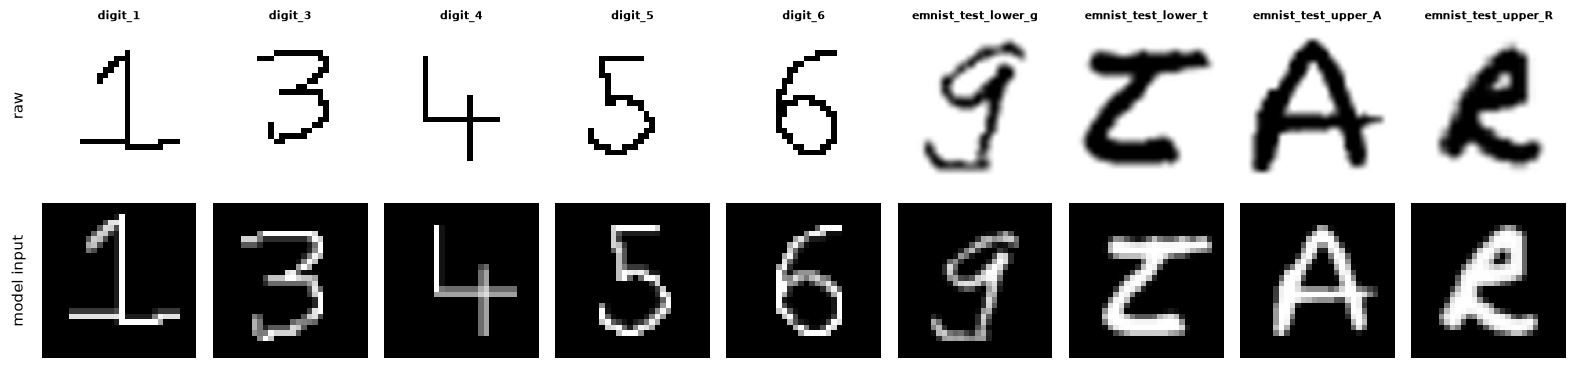

In [9]:
from hcr.preprocess import load_image, to_model_input

files = sorted(Path("samples").glob("*.png"))
fig, axes = plt.subplots(2, len(files), figsize=(1.6 * len(files), 3.6))
for k, f in enumerate(files):
    raw = load_image(f)
    axes[0, k].imshow(raw, cmap="gray"); axes[0, k].set_title(f.stem, fontsize=7); axes[0, k].axis("off")
    axes[1, k].imshow(to_model_input(raw), cmap="gray"); axes[1, k].axis("off")
axes[0, 0].text(-0.1, 0.5, "raw", transform=axes[0, 0].transAxes, rotation=90, va="center", ha="right")
axes[1, 0].text(-0.1, 0.5, "model input", transform=axes[1, 0].transAxes, rotation=90, va="center", ha="right")
plt.tight_layout(); plt.savefig("reports/figures/preprocessing.png"); plt.show()

## 6. Models

`hcr.zoo.build_model(family, num_classes, hidden_layers, units, blocks, dropout, lr, augment)`
builds all four families from a few hyper-parameters so that the **number of hidden layers** (and
width) can be varied systematically. Light on-the-fly augmentation (small rotation, translation,
zoom) is active only during training.

| Family | Structure | Hidden-layer knob |
|---|---|---|
| MLP | Flatten -> `hidden_layers` x [Dense(units, ReLU), BN, Dropout] -> softmax | dense layers |
| Plain CNN | 2 conv stages (2x Conv-BN each) + pooling/dropout -> `hidden_layers` x Dense(units) -> softmax | dense head depth |
| ResNet-style | stem -> `blocks` residual blocks -> global pooling -> `hidden_layers` x Dense -> softmax | residual blocks / head depth |
| CNN + BiLSTM | conv stack -> columns as 14 time-steps -> BiLSTM -> `hidden_layers` x Dense -> softmax | dense head depth |

In [10]:
from hcr.zoo import FAMILIES, build_model, count_params

NUM_CLASSES = len(data.classes)
rows = []
for fam in FAMILIES:
    m = build_model(fam, NUM_CLASSES)           # default sizes
    rows.append({"family": LABELS[fam], "layers": len(m.layers), "parameters": count_params(m)})
display(pd.DataFrame(rows).set_index("family"))

# Layer listing of the ResNet-style model with default settings (the final model in Section 10 uses 4 blocks).
build_model("resnet", NUM_CLASSES).summary(line_length=90)

,layers,parameters
family,,
MLP,12,130142
Plain CNN,24,496958
ResNet-style CNN,31,53550
CNN + BiLSTM,20,328030


Model: "hcr_resnet"

┏━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━━━━━┓
┃ Layer (type)             ┃ Output Shape         ┃      Param # ┃ Connected to          ┃
┡━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━━━━━┩
│ input_layer_4            │ (None, 28, 28, 1)    │            0 │ -                     │
│ (InputLayer)             │                      │              │                       │
├──────────────────────────┼──────────────────────┼──────────────┼───────────────────────┤
│ random_rotation_4        │ (None, 28, 28, 1)    │            0 │ input_layer_4[0][0]   │
│ (RandomRotation)         │                      │              │                       │
├──────────────────────────┼──────────────────────┼──────────────┼───────────────────────┤
│ random_translation_4     │ (None, 28, 28, 1)    │            0 │ random_rotation_4[0]… │
│ (RandomTranslation)      │                      │              │                       │
├──────────────────────────┼──────────────────────┼──────────────┼───────────────────────┤
│ random_zoom_4            │ (None, 28, 28, 1)    │            0 │ random_translation_4… │
│ (RandomZoom)             │                      │              │                       │
├──────────────────────────┼──────────────────────┼──────────────┼───────────────────────┤
│ conv2d_12 (Conv2D)       │ (None, 28, 28, 16)   │          144 │ random_zoom_4[0][0]   │
├──────────────────────────┼──────────────────────┼──────────────┼───────────────────────┤
│ batch_normalization_20   │ (None, 28, 28, 16)   │           64 │ conv2d_12[0][0]       │
│ (BatchNormalization)     │                      │              │                       │
├──────────────────────────┼──────────────────────┼──────────────┼───────────────────────┤
│ activation_5             │ (None, 28, 28, 16)   │            0 │ batch_normalization_… │
│ (Activation)             │                      │              │                       │
├──────────────────────────┼──────────────────────┼──────────────┼───────────────────────┤
│ conv2d_13 (Conv2D)       │ (None, 28, 28, 16)   │        2,304 │ activation_5[0][0]    │
├──────────────────────────┼──────────────────────┼──────────────┼───────────────────────┤
│ batch_normalization_21   │ (None, 28, 28, 16)   │           64 │ conv2d_13[0][0]       │
│ (BatchNormalization)     │                      │              │                       │
├──────────────────────────┼──────────────────────┼──────────────┼───────────────────────┤
│ activation_6             │ (None, 28, 28, 16)   │            0 │ batch_normalization_… │
│ (Activation)             │                      │              │                       │
├──────────────────────────┼──────────────────────┼──────────────┼───────────────────────┤
│ conv2d_14 (Conv2D)       │ (None, 28, 28, 16)   │        2,304 │ activation_6[0][0]    │
├──────────────────────────┼──────────────────────┼──────────────┼───────────────────────┤
│ batch_normalization_22   │ (None, 28, 28, 16)   │           64 │ conv2d_14[0][0]       │
│ (BatchNormalization)     │                      │              │                       │
├──────────────────────────┼──────────────────────┼──────────────┼───────────────────────┤
│ add_2 (Add)              │ (None, 28, 28, 16)   │            0 │ batch_normalization_… │
│                          │                      │              │ activation_5[0][0]    │
├──────────────────────────┼──────────────────────┼──────────────┼───────────────────────┤
│ activation_7             │ (None, 28, 28, 16)   │            0 │ add_2[0][0]           │
│ (Activation)             │                      │              │                       │
├──────────────────────────┼──────────────────────┼──────────────┼───────────────────────┤
│ conv2d_15 (Conv2D)       │ (None, 14, 14, 32)   │        4,608 │ activation_7[0][0]    │
├──────────────────────────┼──────────────────────┼──────────────┼─────────────────────

 Total params: 53,550 (209.18 KB)

 Trainable params: 52,750 (206.05 KB)

 Non-trainable params: 800 (3.12 KB)

In [11]:
# The numbers below come from scripts/bn_momentum_check.py (5 epochs, 30,000 training images, seed 0).
import json
bn = json.loads(Path("experiments/bn_momentum_check.json").read_text())["results"]
cnn_old, cnn_new = bn["cnn"]["0.99"]["val_acc"], bn["cnn"]["0.9"]["val_acc"]
res_old, res_new = bn["resnet"]["0.99"]["val_acc"], bn["resnet"]["0.9"]["val_acc"]
display(Markdown(
    "One thing that cost us time: in our first short runs the training accuracy went up normally, but the "
    "validation accuracy stayed far too low. The cause was batch normalisation. Keras updates its running "
    "statistics with a momentum of 0.99, which is too slow when a run only has a few hundred steps, so the "
    "statistics used at test time were out of date. After the first epoch the CNN had "
    f"{cnn_old[0]:.0%} validation accuracy with 0.99 and {cnn_new[0]:.0%} with 0.9 (ResNet-style CNN: "
    f"{res_old[0]:.0%} and {res_new[0]:.0%}). After 5 epochs it was {cnn_old[-1]:.0%} against {cnn_new[-1]:.0%} "
    f"for the CNN and {res_old[-1]:.0%} against {res_new[-1]:.0%} for the ResNet. All our models use 0.9 and a "
    "unit test checks it."))

One thing that cost us time: in our first short runs the training accuracy went up normally, but the validation accuracy stayed far too low. The cause was batch normalisation. Keras updates its running statistics with a momentum of 0.99, which is too slow when a run only has a few hundred steps, so the statistics used at test time were out of date. After the first epoch the CNN had 5% validation accuracy with 0.99 and 67% with 0.9 (ResNet-style CNN: 2% and 20%). After 5 epochs it was 78% against 80% for the CNN and 8% against 49% for the ResNet. All our models use 0.9 and a unit test checks it.

### 6.1 A short live training run

The sweeps in the next sections took hours on the CPU, so the notebook loads their saved results instead of training again. To see the training happen, the cell below trains a plain CNN for 3 epochs on a random sample of 20,000 training images (about a minute on our CPU). It is only a demonstration, the numbers are not used anywhere else.

In [12]:
rng_live = np.random.default_rng(0)
pick = rng_live.choice(len(data.x_train), 20_000, replace=False)       # random, so every source is included
live_model = build_model("cnn", NUM_CLASSES)
t0 = time.time()
live_hist = live_model.fit(data.x_train[pick], data.y_train[pick],
                           validation_data=(data.x_val[:5000], data.y_val[:5000]),
                           epochs=3, batch_size=256, verbose=2)
display(Markdown(f"Trained for 3 epochs in {time.time() - t0:.0f} seconds. Validation accuracy went from "
                 f"{live_hist.history['val_accuracy'][0]:.1%} to {live_hist.history['val_accuracy'][-1]:.1%} "
                 "on the first 5,000 validation images."))

Epoch 1/3


79/79 - 29s - 361ms/step - accuracy: 0.3115 - loss: 3.1351 - val_accuracy: 0.6006 - val_loss: 1.5508


Epoch 2/3


79/79 - 19s - 245ms/step - accuracy: 0.5222 - loss: 1.8909 - val_accuracy: 0.6984 - val_loss: 1.0684


Epoch 3/3


79/79 - 18s - 233ms/step - accuracy: 0.5990 - loss: 1.4730 - val_accuracy: 0.7548 - val_loss: 0.8430


Trained for 3 epochs in 66 seconds. Validation accuracy went from 60.1% to 75.5% on the first 5,000 validation images.

## 7. Experiment 1: number of epochs

For each of the four models we trained a new network for 2, 5, 10 and 20 epochs. To keep the CPU time reasonable all of these runs use the same 80,000 training images. The learning rate (0.001), batch size (256) and random seed are fixed, and there is no early stopping, because the number of epochs is exactly what we want to change. We compare validation accuracy and leave the test set alone. The helper below trains whatever is missing and simply reloads results that were saved before.

In [13]:
import run_experiments as rx
from hcr.sweeps import load_results, results_frame

rx.stage_epochs(data, print)          # trains missing runs; cached JSON are reused
epochs_df = results_frame(load_results("experiments/results/epochs"))
display(epochs_df.pivot_table(index="epochs", columns="family", values="val_acc").round(4)
        .rename(columns=LABELS).style.format("{:.2%}").set_caption("Validation accuracy vs epochs"))

[epochs 1/16] mlp e=2 h=2 u=128 b=2 seed=0 -> val=0.6621 test=0.6765 (0s)
[epochs 2/16] mlp e=5 h=2 u=128 b=2 seed=0 -> val=0.7304 test=0.7398 (0s)
[epochs 3/16] mlp e=10 h=2 u=128 b=2 seed=0 -> val=0.7581 test=0.7603 (0s)
[epochs 4/16] mlp e=20 h=2 u=128 b=2 seed=0 -> val=0.7772 test=0.7771 (0s)
[epochs 5/16] cnn e=2 h=2 u=128 b=2 seed=0 -> val=0.8022 test=0.8024 (0s)
[epochs 6/16] cnn e=5 h=2 u=128 b=2 seed=0 -> val=0.8253 test=0.8196 (0s)
[epochs 7/16] cnn e=10 h=2 u=128 b=2 seed=0 -> val=0.8345 test=0.8299 (0s)
[epochs 8/16] cnn e=20 h=2 u=128 b=2 seed=0 -> val=0.8405 test=0.8339 (0s)
[epochs 9/16] resnet e=2 h=2 u=128 b=2 seed=0 -> val=0.6526 test=0.6661 (0s)
[epochs 10/16] resnet e=5 h=2 u=128 b=2 seed=0 -> val=0.7117 test=0.7233 (0s)
[epochs 11/16] resnet e=10 h=2 u=128 b=2 seed=0 -> val=0.7606 test=0.7562 (0s)
[epochs 12/16] resnet e=20 h=2 u=128 b=2 seed=0 -> val=0.7719 test=0.7708 (0s)
[epochs 13/16] cnn_bilstm e=2 h=2 u=128 b=2 seed=0 -> val=0.7621 test=0.7652 (0s)
[epochs 1

family,Plain CNN,CNN + BiLSTM,MLP,ResNet-style CNN
epochs,,,,
2,80.22%,76.21%,66.21%,65.26%
5,82.53%,77.66%,73.04%,71.17%
10,83.45%,81.81%,75.81%,76.06%
20,84.05%,83.53%,77.72%,77.19%


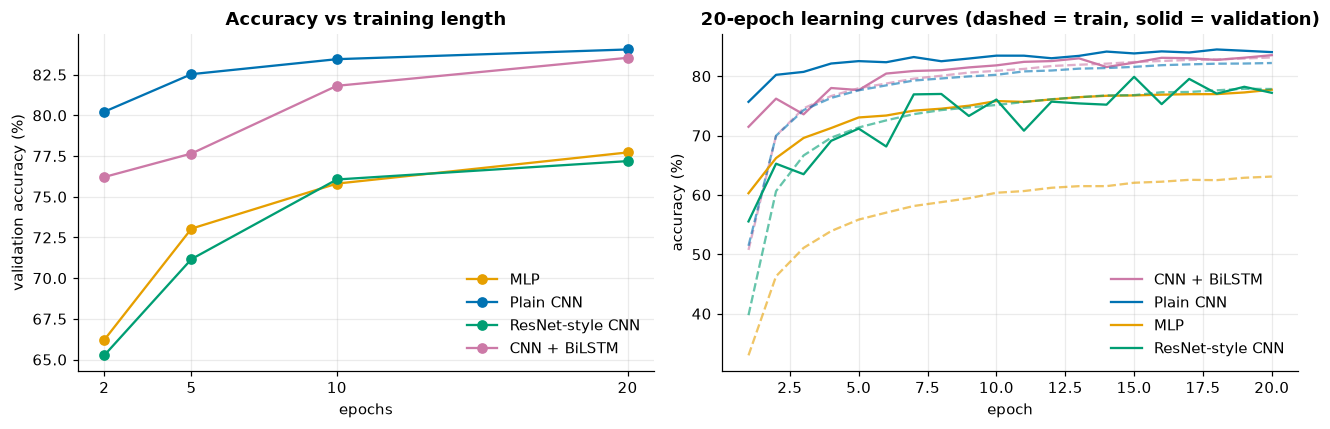

In [14]:
fig, axes = plt.subplots(1, 2, figsize=(12, 4))
for fam in FAMILIES:
    d = epochs_df[epochs_df.family == fam].sort_values("epochs")
    axes[0].plot(d.epochs, d.val_acc * 100, "o-", color=PALETTE[fam], label=LABELS[fam])
axes[0].set(xlabel="epochs", ylabel="validation accuracy (%)", title="Accuracy vs training length")
axes[0].set_xticks([2, 5, 10, 20]); axes[0].legend(frameon=False)

# Learning curves of the longest runs: shows over/under-fitting directly.
for r in load_results("experiments/results/epochs"):
    if r["cfg"]["epochs"] == 20:
        fam = r["cfg"]["family"]; h = r["history"]; e = np.arange(1, len(h["acc"]) + 1)
        axes[1].plot(e, np.array(h["acc"]) * 100, "--", color=PALETTE[fam], alpha=.6)
        axes[1].plot(e, np.array(h["val_acc"]) * 100, "-", color=PALETTE[fam], label=LABELS[fam])
axes[1].set(xlabel="epoch", ylabel="accuracy (%)",
            title="20-epoch learning curves (dashed = train, solid = validation)")
axes[1].legend(frameon=False)
plt.tight_layout(); plt.savefig("reports/figures/exp1_epochs.png"); plt.show()

In [15]:
# Short written summary. It is built from the saved results so the numbers always match the table.
v = {f: epochs_df[epochs_df.family == f].set_index("epochs").val_acc for f in FAMILIES}
first, last = max(FAMILIES, key=lambda f: v[f][2]), min(FAMILIES, key=lambda f: v[f][2])
gain = {f: (v[f][20] - v[f][10]) * 100 for f in FAMILIES}
text = (
    f"The {LABELS[first]} learns fastest: {v[first][2]:.0%} validation accuracy after only 2 epochs. "
    f"The {LABELS[last]} starts lowest at {v[last][2]:.0%}. "
)
if min(gain.values()) > 0:
    text += (
        f"Going from 10 to 20 epochs still helped every model ({min(gain.values()):+.1f} to "
        f"{max(gain.values()):+.1f} points), so none of them had stopped improving. "
    )
else:
    text += "For at least one model, going from 10 to 20 epochs no longer helped. "
best20 = max(FAMILIES, key=lambda f: v[f][20])
text += f"After 20 epochs the best one is the {LABELS[best20]} with {v[best20][20]:.1%}."

# In the right-hand plot the training line can sit below the validation line. That is not a bug:
# training accuracy is measured with augmentation switched on, so the training images are harder.
gap = {r["cfg"]["family"]: (r["history"]["acc"][-1] - r["history"]["val_acc"][-1]) * 100
       for r in load_results("experiments/results/epochs") if r["cfg"]["epochs"] == 20}
low = min(gap, key=gap.get)
if gap[low] < 0:
    text += (
        f"\n\nIn the right plot the training accuracy is below the validation accuracy for some models "
        f"(the {LABELS[low]} by {-gap[low]:.0f} points). This is because the training accuracy is "
        "measured with augmentation turned on, which makes the training images harder."
    )
display(Markdown(text))

The Plain CNN learns fastest: 80% validation accuracy after only 2 epochs. The ResNet-style CNN starts lowest at 65%. Going from 10 to 20 epochs still helped every model (+0.6 to +1.9 points), so none of them had stopped improving. After 20 epochs the best one is the Plain CNN with 84.0%.

In the right plot the training accuracy is below the validation accuracy for some models (the MLP by 15 points). This is because the training accuracy is measured with augmentation turned on, which makes the training images harder.

## 8. Experiment 2: number of hidden layers

Same 80,000 training images again, and again we judge by validation accuracy.
* MLP: 0 to 5 hidden layers, each with 64, 128, 256 or 512 units (all 24 combinations, 10 epochs each)
* Plain CNN and CNN + BiLSTM: 0 to 3 dense hidden layers in the classifier part (8 epochs)
* ResNet-style: 1 to 4 residual blocks (8 epochs)

With 0 hidden layers the features go straight into the output layer.

[depth 1/36] mlp e=10 h=0 u=64 b=2 seed=0 -> val=0.5814 test=0.5855 (0s)
[depth 2/36] mlp e=10 h=0 u=128 b=2 seed=0 -> val=0.5814 test=0.5855 (0s)
[depth 3/36] mlp e=10 h=0 u=256 b=2 seed=0 -> val=0.5814 test=0.5855 (0s)
[depth 4/36] mlp e=10 h=0 u=512 b=2 seed=0 -> val=0.5814 test=0.5855 (0s)
[depth 5/36] mlp e=10 h=1 u=64 b=2 seed=0 -> val=0.6980 test=0.7054 (0s)
[depth 6/36] mlp e=10 h=1 u=128 b=2 seed=0 -> val=0.7509 test=0.7541 (0s)
[depth 7/36] mlp e=10 h=1 u=256 b=2 seed=0 -> val=0.7779 test=0.7784 (0s)
[depth 8/36] mlp e=10 h=1 u=512 b=2 seed=0 -> val=0.7903 test=0.7889 (0s)
[depth 9/36] mlp e=10 h=2 u=64 b=2 seed=0 -> val=0.6949 test=0.7042 (0s)
[depth 10/36] mlp e=10 h=2 u=128 b=2 seed=0 -> val=0.7581 test=0.7603 (0s)
[depth 11/36] mlp e=10 h=2 u=256 b=2 seed=0 -> val=0.7876 test=0.7877 (0s)
[depth 12/36] mlp e=10 h=2 u=512 b=2 seed=0 -> val=0.8021 test=0.8003 (0s)
[depth 13/36] mlp e=10 h=3 u=64 b=2 seed=0 -> val=0.6718 test=0.6866 (0s)
[depth 14/36] mlp e=10 h=3 u=128 b=2 s

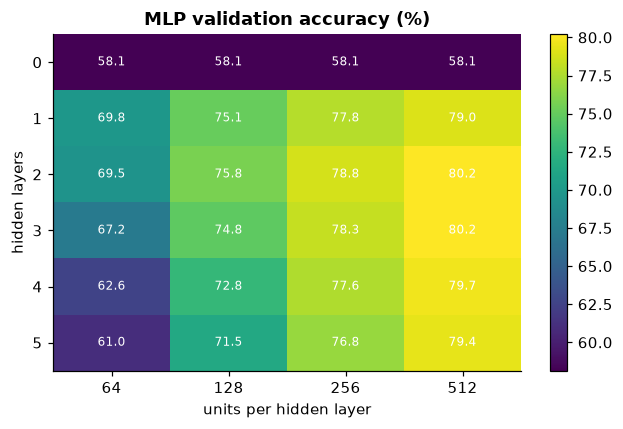

In [16]:
rx.stage_depth(data, print)
depth_df = results_frame(load_results("experiments/results/depth"))

# MLP: depth x width grid as a heat-map
mlp = depth_df[depth_df.family == "mlp"].pivot_table(index="hidden_layers", columns="units", values="val_acc")
fig, ax = plt.subplots(figsize=(6, 4))
im = ax.imshow(mlp.values * 100, cmap="viridis", aspect="auto")
ax.set_xticks(range(mlp.shape[1])); ax.set_xticklabels(mlp.columns)
ax.set_yticks(range(mlp.shape[0])); ax.set_yticklabels(mlp.index)
ax.set(xlabel="units per hidden layer", ylabel="hidden layers", title="MLP validation accuracy (%)")
ax.grid(False)
for i in range(mlp.shape[0]):
    for j in range(mlp.shape[1]):
        ax.text(j, i, f"{mlp.values[i, j]*100:.1f}", ha="center", va="center", color="w", fontsize=8)
plt.colorbar(im); plt.tight_layout(); plt.savefig("reports/figures/exp2_mlp_grid.png"); plt.show()

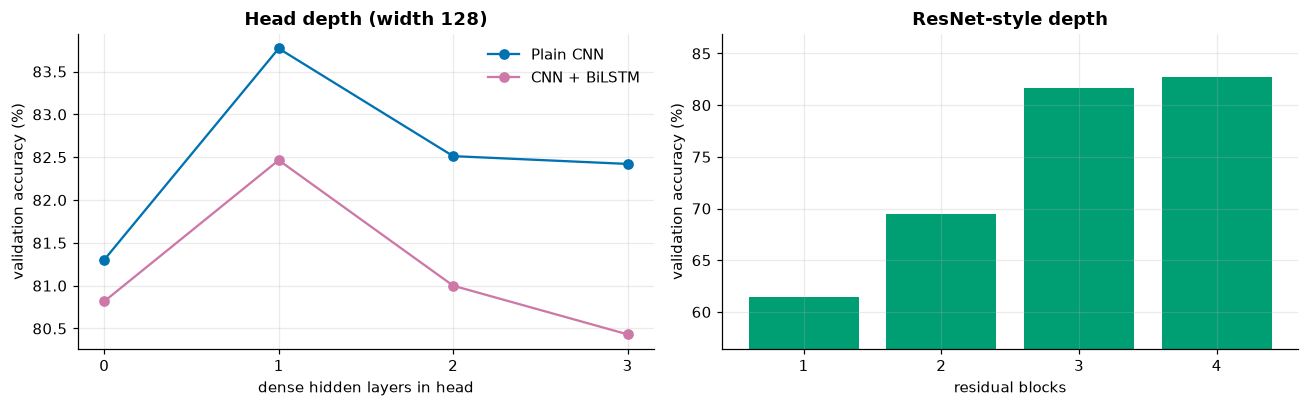

For the MLP the big jump is from 0 to 1 hidden layer (58% to 79% with the best width). After that, more layers help much less and width matters more: the best MLP has 2 layers of 512 units (80.2%). (With 0 hidden layers the width does nothing, so the first row of the heat-map is one model four times.) For the Plain CNN the number of dense layers matters much less (best and worst differ by 2.5 points); the best has 1 (83.8%). For the CNN + BiLSTM the number of dense layers matters much less (best and worst differ by 2.0 points); the best has 1 (82.5%). The ResNet-style CNN does best with 4 residual blocks (82.7%). For the convolutional models most of the work is clearly done by the convolutions, not by the dense layers.

In [17]:
fig, axes = plt.subplots(1, 2, figsize=(12, 3.8))
for fam in ("cnn", "cnn_bilstm"):
    d = depth_df[depth_df.family == fam].sort_values("hidden_layers")
    axes[0].plot(d.hidden_layers, d.val_acc * 100, "o-", color=PALETTE[fam], label=LABELS[fam])
axes[0].set(xlabel="dense hidden layers in head", ylabel="validation accuracy (%)",
            title="Head depth (width 128)"); axes[0].set_xticks([0, 1, 2, 3]); axes[0].legend(frameon=False)

d = depth_df[depth_df.family == "resnet"].sort_values("blocks")
axes[1].bar(d.blocks.astype(str), d.val_acc * 100, color=PALETTE["resnet"])
axes[1].set(xlabel="residual blocks", ylabel="validation accuracy (%)", title="ResNet-style depth")
lo = depth_df[depth_df.family != "mlp"].val_acc.min() * 100
axes[1].set_ylim(max(lo - 5, 0), None)
plt.tight_layout(); plt.savefig("reports/figures/exp2_depth.png"); plt.show()

# Written summary, built from the table above
m = depth_df[depth_df.family == "mlp"]
best_m = m.loc[m.val_acc.idxmax()]
zero, one = m[m.hidden_layers == 0].val_acc.max(), m[m.hidden_layers == 1].val_acc.max()
text = (
    f"For the MLP the big jump is from 0 to 1 hidden layer ({zero:.0%} to {one:.0%} with the best width). "
    f"After that, more layers help much less and width matters more: the best MLP has "
    f"{int(best_m.hidden_layers)} layers of {int(best_m.units)} units ({best_m.val_acc:.1%}). "
)
if m[m.hidden_layers == 0].val_acc.nunique() == 1:
    text += "(With 0 hidden layers the width does nothing, so the first row of the heat-map is one model four times.) "
for fam in ("cnn", "cnn_bilstm"):
    d = depth_df[depth_df.family == fam]
    b = d.loc[d.val_acc.idxmax()]
    spread = (d.val_acc.max() - d.val_acc.min()) * 100
    text += (
        f"For the {LABELS[fam]} the number of dense layers matters much less (best and worst differ by "
        f"{spread:.1f} points); the best has {int(b.hidden_layers)} ({b.val_acc:.1%}). "
    )
d = depth_df[depth_df.family == "resnet"]
b = d.loc[d.val_acc.idxmax()]
text += f"The ResNet-style CNN does best with {int(b.blocks)} residual blocks ({b.val_acc:.1%}). "
text += "For the convolutional models most of the work is clearly done by the convolutions, not by the dense layers."
display(Markdown(text))

## 9. Experiment 3: comparing the models

Now we take the best settings of each model from Experiment 2 and train each one three times with different random seeds (0, 1 and 2), this time on 200,000 images for 12 epochs. Averaging over seeds tells us whether a difference between two models is real or just luck. The model with the highest mean validation accuracy is the winner.

In [18]:
rx.stage_comparison(data, print)
cmp_df = results_frame(load_results("experiments/results/comparison"))

agg = cmp_df.groupby("family").agg(
    val_mean=("val_acc", "mean"), val_std=("val_acc", "std"),
    test_mean=("test_acc", "mean"), test_std=("test_acc", "std"),
    f1_mean=("test_f1", "mean"), params=("params", "first"),
    train_s=("train_seconds", "mean"),
).sort_values("val_mean", ascending=False)
view = agg.copy()
view.index = [LABELS[i] for i in view.index]
view["validation"] = [f"{m:.2%} +/- {s:.2%}" for m, s in zip(agg.val_mean, agg.val_std.fillna(0))]
view["test"] = [f"{m:.2%} +/- {s:.2%}" for m, s in zip(agg.test_mean, agg.test_std.fillna(0))]
view["macro-F1 (test)"] = agg.f1_mean.round(4).values
view["train time (s)"] = agg.train_s.round(0).astype(int).values
display(view[["validation", "test", "macro-F1 (test)", "params", "train time (s)"]])

[comparison 1/12] cnn_bilstm e=12 h=1 u=128 b=2 seed=0 -> val=0.8225 test=0.8132 (0s)
[comparison 2/12] cnn_bilstm e=12 h=1 u=128 b=2 seed=1 -> val=0.8335 test=0.8251 (0s)
[comparison 3/12] cnn_bilstm e=12 h=1 u=128 b=2 seed=2 -> val=0.8247 test=0.8177 (0s)
[comparison 4/12] cnn e=12 h=1 u=128 b=2 seed=0 -> val=0.8455 test=0.8367 (0s)
[comparison 5/12] cnn e=12 h=1 u=128 b=2 seed=1 -> val=0.8421 test=0.8337 (0s)
[comparison 6/12] cnn e=12 h=1 u=128 b=2 seed=2 -> val=0.8357 test=0.8269 (0s)
[comparison 7/12] mlp e=12 h=2 u=512 b=2 seed=0 -> val=0.8295 test=0.8224 (0s)
[comparison 8/12] mlp e=12 h=2 u=512 b=2 seed=1 -> val=0.8246 test=0.8196 (0s)
[comparison 9/12] mlp e=12 h=2 u=512 b=2 seed=2 -> val=0.8225 test=0.8155 (0s)
[comparison 10/12] resnet e=12 h=1 u=128 b=4 seed=0 -> val=0.8380 test=0.8303 (0s)
[comparison 11/12] resnet e=12 h=1 u=128 b=4 seed=1 -> val=0.8478 test=0.8414 (0s)
[comparison 12/12] resnet e=12 h=1 u=128 b=4 seed=2 -> val=0.8491 test=0.8392 (0s)


,validation,test,macro-F1 (test),params,train time (s)
ResNet-style CNN,84.49% +/- 0.61%,83.69% +/- 0.59%,0.7139,337838,766
Plain CNN,84.11% +/- 0.50%,83.24% +/- 0.50%,0.6963,479934,832
CNN + BiLSTM,82.69% +/- 0.58%,81.87% +/- 0.60%,0.6723,311006,557
MLP,82.55% +/- 0.36%,81.91% +/- 0.35%,0.6657,716894,131


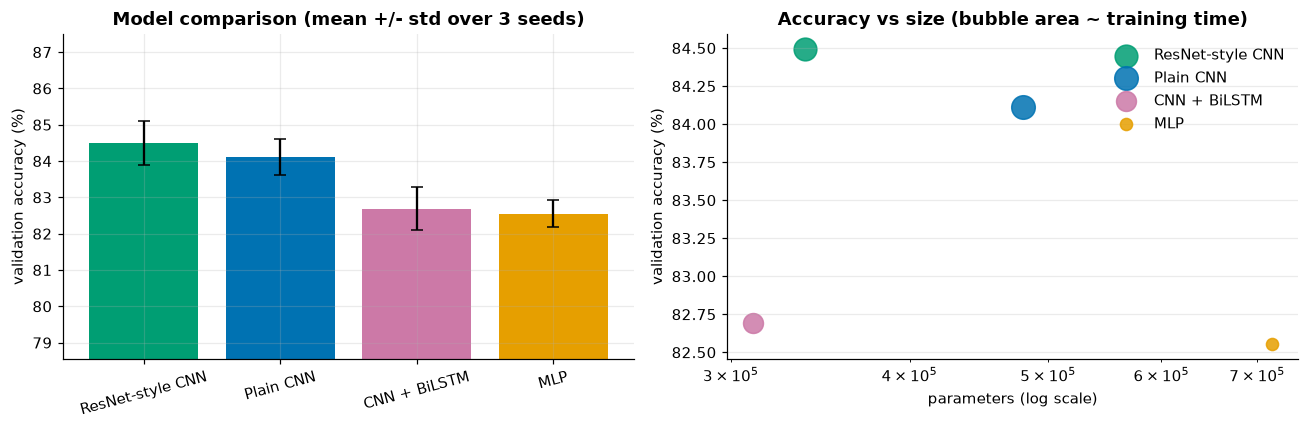

The ResNet-style CNN comes out on top with 84.5% validation accuracy, 0.38 points ahead of the Plain CNN. But the seeds themselves differ by about 0.61 points, so the two are really tied. The ResNet-style CNN has 337,838 parameters against 479,934 and needs about 13 min per run against 14. The MLP is last with 82.6%, only 1.9 points behind the winner.

In [19]:
fig, axes = plt.subplots(1, 2, figsize=(12, 4))
order = list(agg.index)
axes[0].bar([LABELS[f] for f in order], agg.val_mean * 100, yerr=agg.val_std.fillna(0) * 100,
            color=[PALETTE[f] for f in order], capsize=4)
axes[0].set(ylabel="validation accuracy (%)", title="Model comparison (mean +/- std over 3 seeds)")
axes[0].set_ylim(agg.val_mean.min() * 100 - 4, agg.val_mean.max() * 100 + 3); axes[0].tick_params(axis="x", rotation=15)

for f in order:
    axes[1].scatter(agg.loc[f, "params"], agg.loc[f, "val_mean"] * 100, s=agg.loc[f, "train_s"] / 4 + 30,
                    color=PALETTE[f], label=LABELS[f], alpha=.85)
axes[1].set_xscale("log")
axes[1].set(xlabel="parameters (log scale)", ylabel="validation accuracy (%)",
            title="Accuracy vs size (bubble area ~ training time)"); axes[1].legend(frameon=False)
plt.tight_layout(); plt.savefig("reports/figures/exp3_comparison.png"); plt.show()

best, second = agg.index[0], agg.index[1]
gap = (agg.val_mean.iloc[0] - agg.val_mean.iloc[1]) * 100
noise = max(agg.val_std.iloc[0], agg.val_std.iloc[1]) * 100
text = (
    f"The {LABELS[best]} comes out on top with {agg.val_mean.iloc[0]:.1%} validation accuracy, "
    f"{gap:.2f} points ahead of the {LABELS[second]}. "
)
if gap > noise:
    text += f"The seeds differ by about {noise:.2f} points, so the lead looks real. "
else:
    text += f"But the seeds themselves differ by about {noise:.2f} points, so the two are really tied. "
text += (
    f"The {LABELS[best]} has {int(agg.params.iloc[0]):,} parameters against {int(agg.params.iloc[1]):,} "
    f"and needs about {agg.train_s.iloc[0] / 60:.0f} min per run against {agg.train_s.iloc[1] / 60:.0f}. "
    f"The {LABELS[agg.index[-1]]} is last with {agg.val_mean.iloc[-1]:.1%}, only "
    f"{(agg.val_mean.iloc[0] - agg.val_mean.iloc[-1]) * 100:.1f} points behind the winner."
)
display(Markdown(text))

## 10. Final model

For the final model we take the winning family with its best settings from Experiment 2 and train it on the whole training set (742,742 images) instead of a subset. It is saved as `models/ocr_best.keras`, with the list of classes in `models/ocr_best.json`.

final winner (mean val over seeds): resnet
final resnet: val=0.8550 test=0.8474


The final model is a `resnet` with 4 residual blocks and 1 dense layer of 128 units, 337,838 parameters in total. We trained it for 10 epochs (fewer than the 20 epochs of the sweep, to save CPU time), which took 36 minutes. Validation accuracy is 85.50%, test accuracy is **84.74%** and the macro-F1 on the test set is 0.739.

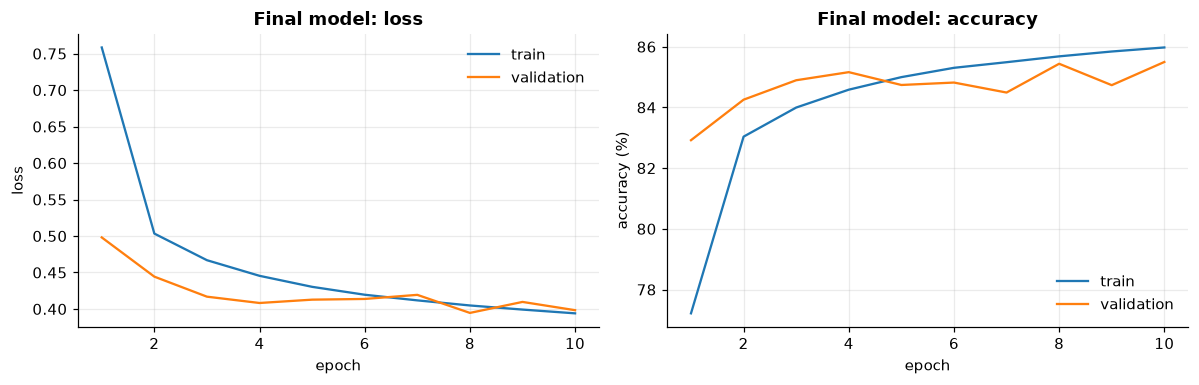

In [20]:
rx.stage_final(data, print)
final = load_results("experiments/results/final")[0]
cfg = final["cfg"]
sweep_longest = int(epochs_df.epochs.max())
why = (
    "the longest run in the epoch sweep, because more epochs were still helping there"
    if cfg["epochs"] >= sweep_longest
    else f"fewer than the {sweep_longest} epochs of the sweep, to save CPU time"
)
display(Markdown(
    f"The final model is a `{cfg['family']}` with {cfg['blocks']} residual blocks and {cfg['hidden_layers']} "
    f"dense layer{'s' if cfg['hidden_layers'] != 1 else ''} of {cfg['units']} units, {final['params']:,} parameters in total. We trained it for "
    f"{cfg['epochs']} epochs ({why}), which took {final['train_seconds'] / 60:.0f} minutes. "
    f"Validation accuracy is {final['val_acc']:.2%}, test accuracy is **{final['test_acc']:.2%}** "
    f"and the macro-F1 on the test set is {final['test_f1']:.3f}."))

h = final["history"]; e = np.arange(1, len(h["acc"]) + 1)
fig, axes = plt.subplots(1, 2, figsize=(11, 3.6))
axes[0].plot(e, h["loss"], label="train"); axes[0].plot(e, h["val_loss"], label="validation")
axes[0].set(xlabel="epoch", ylabel="loss", title="Final model: loss"); axes[0].legend(frameon=False)
axes[1].plot(e, np.array(h["acc"]) * 100, label="train"); axes[1].plot(e, np.array(h["val_acc"]) * 100, label="validation")
axes[1].set(xlabel="epoch", ylabel="accuracy (%)", title="Final model: accuracy"); axes[1].legend(frameon=False)
plt.tight_layout(); plt.savefig("reports/figures/final_history.png"); plt.show()

## 11. Evaluation and error analysis

Now we load the saved model, predict the whole test set and look at where it does well and where it fails: by character group, by data source, and with look-alike characters counted as the same.

In [21]:
from hcr.evaluate import (predict_classes, accuracy_by_group, case_insensitive_accuracy,
                          confusion_matrix, top_confusions, per_class_f1, error_examples)

best_model = keras.models.load_model("models/ocr_best.keras")
y_true = data.y_test
y_pred = predict_classes(best_model, data.x_test)

strict = float((y_pred == y_true).mean())
lenient = case_insensitive_accuracy(y_true, y_pred, data.classes, AMBIGUOUS_GROUPS)
by_group = accuracy_by_group(y_true, y_pred, groups)
by_source = {SOURCE[s]: float((y_pred[data.source_test == s] == y_true[data.source_test == s]).mean())
             for s in SOURCE}

table = pd.DataFrame({
    "accuracy": {"ALL (strict)": strict, "ALL (confusable groups merged)": lenient,
                 **{f"group: {g}": v for g, v in by_group.items()},
                 **{f"source: {k}": v for k, v in by_source.items()}},
})
display(table.style.format("{:.2%}"))

,accuracy
ALL (strict),84.74%
ALL (confusable groups merged),94.45%
group: digits,95.32%
group: upper,80.76%
group: lower,67.55%
group: symbols,88.85%
source: EMNIST (handwritten),85.43%
source: HASYv2 (handwritten),86.67%
source: Fonts (printed),73.26%


In [22]:
# --- Honest uncertainty for the small handwritten-symbol test set (Wilson 95% interval) ---
def wilson(k, n, z=1.96):
    p = k / n
    centre = (p + z * z / (2 * n)) / (1 + z * z / n)
    half = z * np.sqrt(p * (1 - p) / n + z * z / (4 * n * n)) / (1 + z * z / n)
    return centre - half, centre + half

mask = data.source_test == 1
k, n = int((y_pred[mask] == y_true[mask]).sum()), int(mask.sum())
lo, hi = wilson(k, n)
display(Markdown(
    f"On the {n} handwritten HASYv2 test symbols the model gets {k} right ({k/n:.1%}). "
    f"With so few images the 95% interval is wide: {lo:.1%} to {hi:.1%}."))

On the 165 handwritten HASYv2 test symbols the model gets 143 right (86.7%). With so few images the 95% interval is wide: 80.6% to 91.0%.

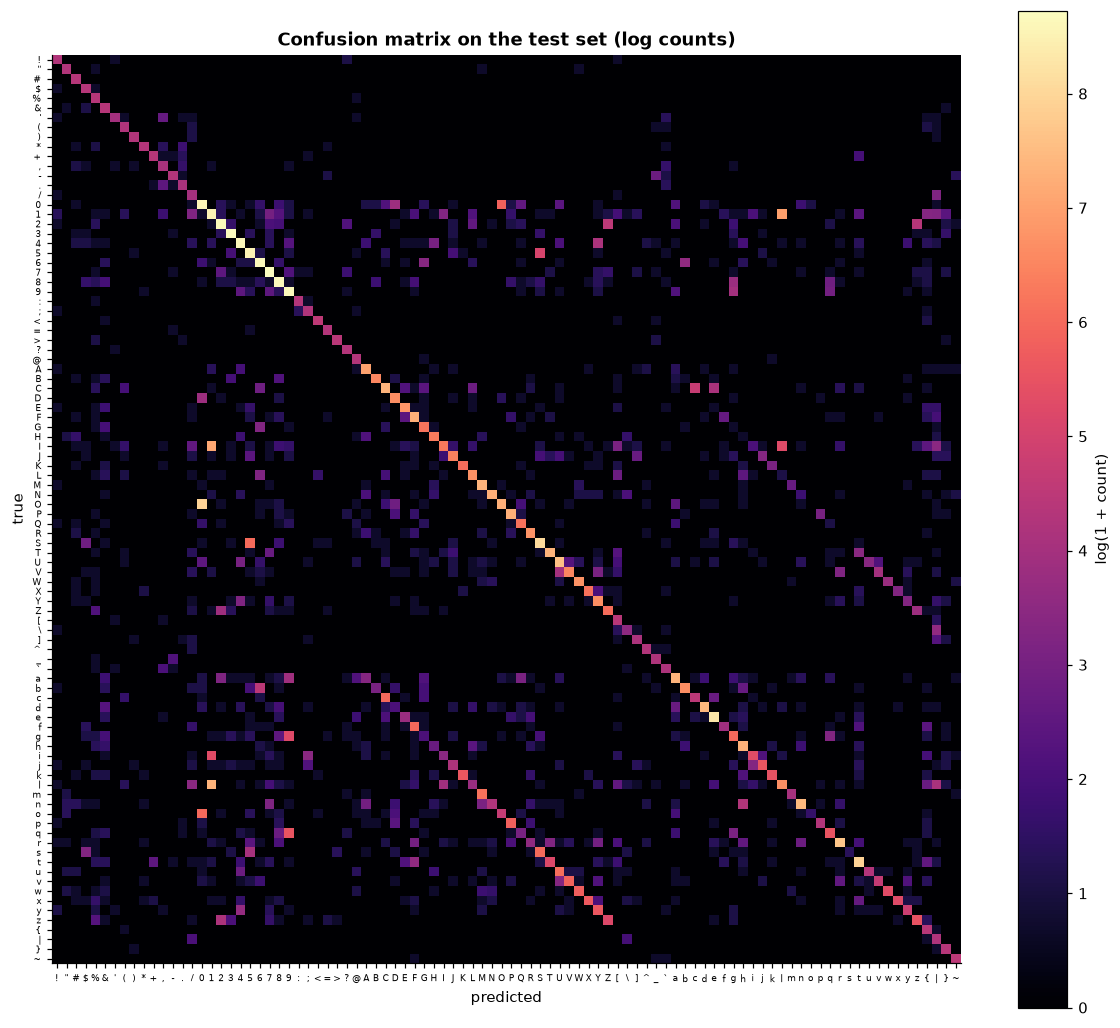

In [23]:
# --- Confusion matrix of all 94 classes (log colour scale so rare errors are visible) ---
cm = confusion_matrix(y_true, y_pred, len(data.classes))
fig, ax = plt.subplots(figsize=(11, 9.5))
im = ax.imshow(np.log1p(cm), cmap="magma")
ax.set_xticks(range(94)); ax.set_xticklabels(data.classes, fontsize=6)
ax.set_yticks(range(94)); ax.set_yticklabels(data.classes, fontsize=6)
ax.set(xlabel="predicted", ylabel="true", title="Confusion matrix on the test set (log counts)")
ax.grid(False); plt.colorbar(im, label="log(1 + count)")
plt.tight_layout(); plt.savefig("reports/figures/confusion_matrix.png"); plt.show()

In [24]:
# --- Which confusions dominate? ----------------------------------------------------------
top = top_confusions(cm, data.classes, k=15)
conf_df = pd.DataFrame(top, columns=["true", "predicted", "count"])
total_err = int((y_pred != y_true).sum())
conf_df["share of all errors"] = (conf_df["count"] / total_err).map("{:.1%}".format)
display(conf_df)

merged = {frozenset(g) for g in AMBIGUOUS_GROUPS}
def is_ambiguous(a, b):
    return any(a in g and b in g for g in AMBIGUOUS_GROUPS)
amb_errors = sum(c for t, p, c in top_confusions(cm, data.classes, k=10_000) if is_ambiguous(t, p))
display(Markdown(
    f"{amb_errors / total_err:.1%} of the {total_err:,} mistakes are between characters that look the same "
    "without context, like c/C, o/O/0 and l/I/1. A classifier that sees one glyph at a time cannot really "
    "fix those, so this is a limit of the task more than a flaw in the model."))

,true,predicted,count,share of all errors
0,O,0,2743,14.6%
1,l,1,1567,8.3%
2,I,1,1253,6.6%
3,1,l,1063,5.6%
4,m,M,476,2.5%
5,u,U,441,2.3%
6,S,5,412,2.2%
7,s,S,409,2.2%
8,o,0,394,2.1%
9,f,F,390,2.1%


63.6% of the 18,851 mistakes are between characters that look the same without context, like c/C, o/O/0 and l/I/1. A classifier that sees one glyph at a time cannot really fix those, so this is a limit of the task more than a flaw in the model.

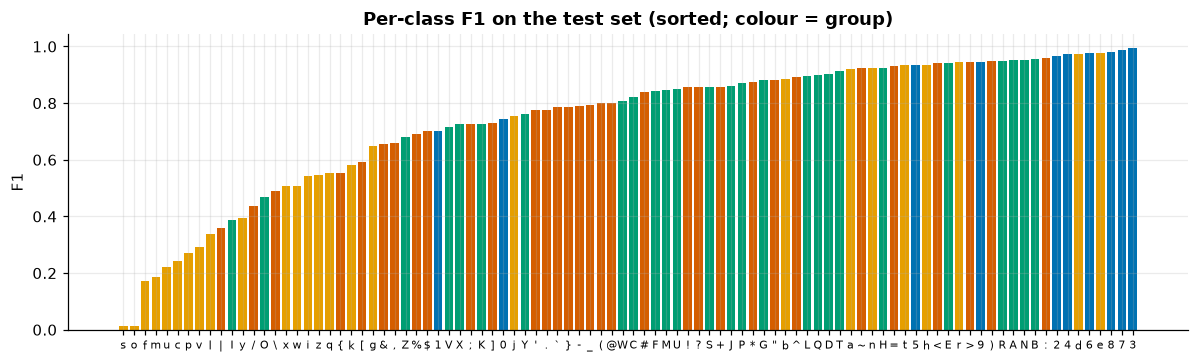

The 12 characters with the lowest F1 are `s` (0.01), `o` (0.01), `f` (0.17), `m` (0.19), `u` (0.22), `c` (0.24), `p` (0.27), `v` (0.29), `l` (0.34), `|` (0.36), `I` (0.39), `y` (0.39). 11 of them belong to a look-alike group.

In [25]:
# --- Per-class F1: the hardest and easiest characters -------------------------------------
f1 = pd.Series(per_class_f1(y_true, y_pred, data.classes)).sort_values()
fig, ax = plt.subplots(figsize=(11, 3.4))
ax.bar(range(len(f1)), f1.values, color=[group_colour[group_of[data.classes.index(c)]] for c in f1.index])
ax.set_xticks(range(len(f1))); ax.set_xticklabels(f1.index, fontsize=7)
ax.set(ylabel="F1", title="Per-class F1 on the test set (sorted; colour = group)")
plt.tight_layout(); plt.savefig("reports/figures/per_class_f1.png"); plt.show()
amb_chars = set().union(*map(set, AMBIGUOUS_GROUPS))
worst = list(f1.head(12).index)
display(Markdown(
    "The 12 characters with the lowest F1 are " + ", ".join(f"`{c}` ({f1[c]:.2f})" for c in worst) + ". "
    f"{sum(c in amb_chars for c in worst)} of them belong to a look-alike group."))

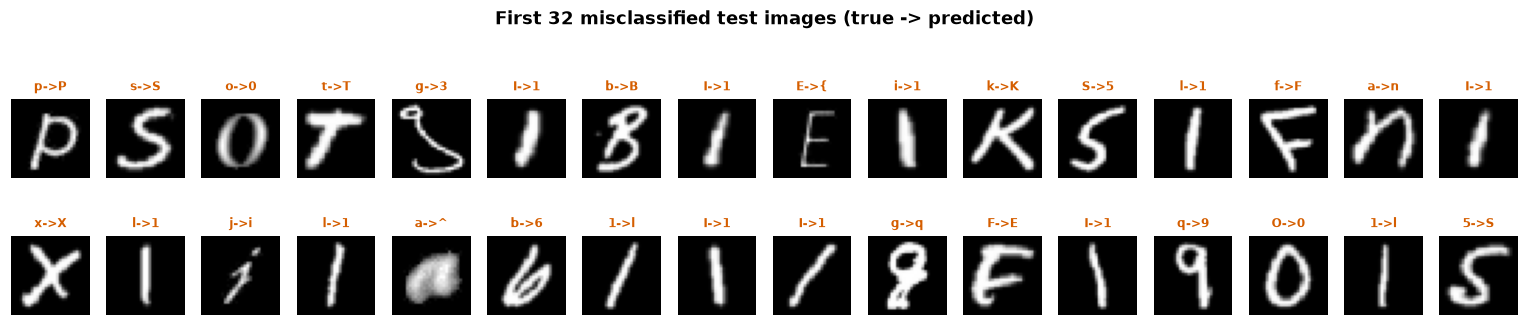

In [26]:
# --- Gallery of mistakes -------------------------------------------------------------------
idx = error_examples(data.x_test, y_true, y_pred, 32)
fig, axes = plt.subplots(2, 16, figsize=(14, 3.4))
for ax, i in zip(axes.ravel(), idx):
    ax.imshow(data.x_test[i, ..., 0], cmap="gray"); ax.axis("off")
    ax.set_title(f"{data.classes[y_true[i]]}->{data.classes[y_pred[i]]}", fontsize=8, color="#D55E00")
plt.suptitle("First 32 misclassified test images (true -> predicted)", fontweight="bold")
plt.tight_layout(); plt.savefig("reports/figures/error_gallery.png"); plt.show()

## 12. Live demo

Two small demos, both using the same preprocessing that any image from a user would go through. First the sample images in `samples/`, then a line of printed text that we cut into single characters and read one by one. The second one shows that the whole pipeline works from an image to text. It is printed text though, so it says little about handwriting.

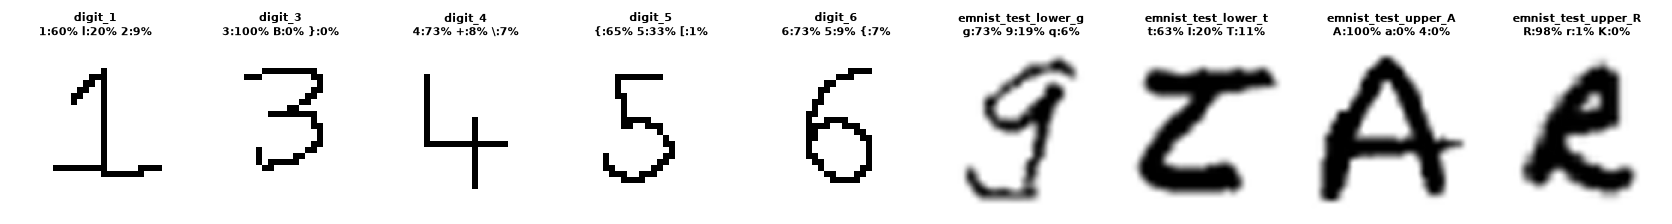

In [27]:
from hcr.predict import Predictor

predictor = Predictor("models/ocr_best.keras")      # loads the model + class list
fig, axes = plt.subplots(1, len(files), figsize=(1.7 * len(files), 2.3))
for ax, f in zip(np.atleast_1d(axes), files):
    top3 = predictor.predict(f, top_k=3)
    ax.imshow(load_image(f), cmap="gray"); ax.axis("off")
    ax.set_title(f"{f.stem}\n" + " ".join(f"{c}:{p:.0%}" for c, p in top3), fontsize=7)
plt.tight_layout(); plt.savefig("reports/figures/demo_samples.png"); plt.show()

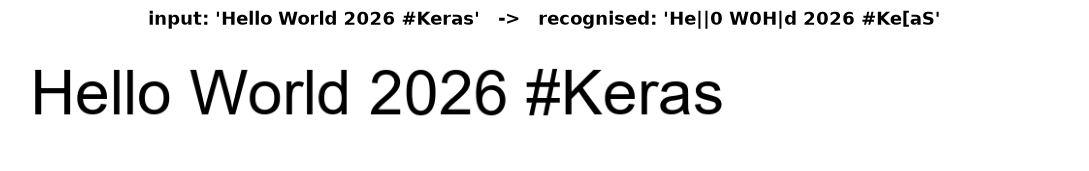

characters correct: 15 / 23 (font: arial.ttf)


Out of 8 wrong characters, **6** are look-alike pairs that no isolated-glyph classifier can separate (`l`->`|`, `l`->`|`, `o`->`0`, `o`->`0`, `l`->`|`, `s`->`S`). The other **2** (`r`->`H`, `r`->`[`) are genuine model mistakes. `arial.ttf` is a **training** font for this model, so even a font it was trained on is not read perfectly. A possible reason, which we did not test, is that after cropping a printed `r` is just a short stem with a small arm, which can look like a bracket. Printed text is also harder for this model than handwriting (per-source accuracy in Section 11).

In [28]:
# --- End-to-end: render a line of text, segment characters, classify each -----------------
import cv2
from PIL import Image, ImageDraw, ImageFont
from hcr.fonts import discover_fonts

TEXT = "Hello World 2026 #Keras"
font_path = next(p for p in discover_fonts() if "arial" in p.name.lower() or "segoeui" in p.name.lower())
font = ImageFont.truetype(str(font_path), 64)
canvas = Image.new("L", (1100, 130), 255)
ImageDraw.Draw(canvas).text((20, 25), TEXT, font=font, fill=0)
line = np.array(canvas)

# Connected components of the (inverted, binarised) line = one blob per glyph here.
_, bw = cv2.threshold(255 - line, 0, 255, cv2.THRESH_BINARY + cv2.THRESH_OTSU)
n, _, stats, _ = cv2.connectedComponentsWithStats(bw)
boxes = sorted([stats[i] for i in range(1, n) if stats[i][4] > 30], key=lambda s: s[0])

out, prev_right = "", None
for x, y, w, h, _a in boxes:
    if prev_right is not None and x - prev_right > 18:   # a wide gap means a space
        out += " "
    glyph = line[max(y - 4, 0): y + h + 4, max(x - 4, 0): x + w + 4]
    out += predictor.predict(glyph, top_k=1)[0][0]
    prev_right = x + w

fig, ax = plt.subplots(figsize=(10, 1.8)); ax.imshow(line, cmap="gray"); ax.axis("off")
ax.set_title(f"input: {TEXT!r}   ->   recognised: {out!r}")
plt.tight_layout(); plt.savefig("reports/figures/demo_line.png"); plt.show()
print("characters correct:", sum(a == b for a, b in zip(out, TEXT)), "/", len(TEXT), f"(font: {font_path.name})")

# Which mistakes are the unavoidable look-alike kind and which are genuine model errors?
wrong = [(a, b) for a, b in zip(TEXT, out) if a != b and a != " "]
look_alike = [(a, b) for a, b in wrong if is_ambiguous(a, b)]
genuine = [(a, b) for a, b in wrong if not is_ambiguous(a, b)]
fmt = lambda pairs: ", ".join(f"`{a}`->`{b}`" for a, b in pairs) or "none"
# Was the demo font seen in training? Recompute the same font split that built the dataset.
from hcr.fonts import split_fonts

_trainval, _test = split_fonts(discover_fonts(), 42)
_train, _val = split_fonts(_trainval, 43, 0.1)
role = "training" if font_path in _train else "validation" if font_path in _val else "test"
seen = (
    f"`{font_path.name}` is a **{role}** font for this model"
    + (", so even a font it was trained on is not read perfectly. " if role == "training" else ". ")
)
display(Markdown(
    f"Out of {len(wrong)} wrong characters, **{len(look_alike)}** are look-alike pairs that no isolated-glyph "
    f"classifier can separate ({fmt(look_alike)}). The other **{len(genuine)}** ({fmt(genuine)}) are genuine "
    f"model mistakes. {seen}"
    "A possible reason, which we did not test, is that after cropping a printed `r` is just a short stem with "
    "a small arm, which can look like a bracket. Printed text is also harder for this model than handwriting "
    "(per-source accuracy in Section 11)."))

## 13. Limitations

* 15 of the 32 symbols only have printed training and test data. The font test split mostly checks fonts the model has not seen, which is not the same as new handwriting, and bold/italic siblings of training fonts can end up in the test set (Section 4.2).
* The handwritten symbol test set is small (165 images). One aggregate HASYv2 writer id supplies about 89% of the handwritten symbol samples and has to stay in training, so those results have wide intervals (Section 11). For several symbols that HASYv2 covers (for example `+ - < >`) printed fonts are most of the training images (table in Section 4).
* After the crop and rescale, capital and small `c k m o p s u v w x y z`, the characters `l I 1 |` and the marks `. , '` look the same. Telling them apart needs context (neighbouring characters, position on the line, size), which a single-glyph classifier does not have. Our merged accuracy only merges the letter and `l I 1 |` groups, not the marks, and `f`/`F` is not merged either.
* A small share of the printed training images (about 3%) are almost blank after the augmentation, and very thin symbols like `[ ] |` can become a single slanted stroke that looks like `/` or `\`.
* The ResNet-style models have noisy validation curves in short runs (the accuracy can jump by several points from one epoch to the next), so single sweep points for the ResNet are less reliable than for the plain CNN. That is one reason we repeated the finalists with three seeds.
* The final model was trained for 10 epochs to save CPU time, while the epoch sweep suggests that more epochs would still help a little.
* Everything ran on the CPU, so the sweeps use training subsets (80k and 200k images) and a small epoch budget. The accuracies from the sweeps are therefore probably lower than what the full data and longer training would give. Only the final model uses all the training images.
* We used one validation split. Seed-to-seed variation is only measured for the four finalists in Experiment 3.
* The line demo cuts characters out with connected components, which breaks for characters made of several parts (`i`, `j`, `!`, `:`, `;`, `=`, `%`). A real document OCR system would need a proper text detector and a sequence model.

## 14. Conclusion and future work

We built a 94-class OCR dataset with separate test fonts and writers, changed the number of epochs and the number of hidden layers, compared four Keras models over several seeds and trained the best one on the full data. The final test accuracy is in the abstract and in Section 10. Strict accuracy is clearly lower than accuracy with look-alike characters merged, and most of the remaining mistakes are exactly those look-alikes. That suggests the next step is a model that sees context, for example a CRNN with CTC loss that reads whole words instead of single characters.

## References
1. LeCun, Bottou, Bengio, Haffner (1998). *Gradient-based learning applied to document recognition.* Proc. IEEE 86(11).
2. Cohen, Afshar, Tapson, van Schaik (2017). *EMNIST: an extension of MNIST to handwritten letters.* arXiv:1702.05373.
3. Thoma (2017). *The HASYv2 dataset.* arXiv:1701.08380.
4. He, Zhang, Ren, Sun (2016). *Deep residual learning for image recognition.* CVPR.
5. Ioffe, Szegedy (2015). *Batch normalization: accelerating deep network training by reducing internal covariate shift.* ICML.
6. Srivastava, Hinton, Krizhevsky, Sutskever, Salakhutdinov (2014). *Dropout.* JMLR 15.
7. Hochreiter, Schmidhuber (1997). *Long short-term memory.* Neural Computation 9(8).
8. Schuster, Paliwal (1997). *Bidirectional recurrent neural networks.* IEEE Trans. Signal Processing 45(11).
9. Shi, Bai, Yao (2017). *An end-to-end trainable neural network for image-based sequence recognition (CRNN).* IEEE TPAMI 39(11).
10. Kingma, Ba (2015). *Adam: a method for stochastic optimization.* ICLR.